In [1]:
import sys

sys.path.append('..')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import metrics
from sklearn.metrics import auc, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import os
import random
from natsort import natsorted, index_natsorted

import torch
import torchvision
from PIL import Image
import time
import copy
from tqdm import tqdm
import torchvision.models as models


from torch.utils.data import WeightedRandomSampler

from typing import Any, Callable, cast, Dict, List, Optional, Tuple, Union

from multi_to_binary import multi_to_binary

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


In [2]:
# parameters
path = '../data/semi-processed/supervised/multiview'
seed = 42
image_size = (150, 200)
batch_size = 96

In [18]:
growing_multiview_training = True
if growing_multiview_training:
    training_dir = f'../data/semi-processed/supervised/growing_multiview_training'
    growing = '_growing'
else:
    growing = ''
    training_dir = f'{path}/train'
    
mask = False
if mask:
    masked = '_mask'
else:
    masked = ''
    
selected_class = 'multiclass'
pretraining = 'no_pretraining'

    
print(f'Using {training_dir} for training')

Using ../data/semi-processed/supervised/growing_multiview_training for training


In [19]:
   
# Import the W&B Python Library 
import wandb   

run = wandb.init(
    project="echo_view_classification",
)

wandb.config = {
    "batch_size": batch_size,
}

wandb: WARNING Source type is set to 'repo' but some required information is missing from the environment. A job will not be created from this run. See https://docs.wandb.ai/guides/launch/create-job


loss,█▂▂▁▁▁▁▁▁▁
val_loss,▁▂▃▆▁▆▇███
loss,0.01121
val_loss,0.25613


In [20]:
# Specifying data augmentation transforms

class transforms_composed:
    """Rotate by one of the given angles."""

    def __init__(self, mode, apply=True, mask=False):
        self.mode = mode
        self.mask=False
        self.size = (200,150)
        if mask:
            self.mask = True
            mask = Image.open('../assets/dicom-mask.png')
            mask.load()
            mask = mask.resize(self.size,Image.NEAREST)
            masking_array = (np.array(mask)[:,:,3])
            masking_array[masking_array!=0]=1
            self.masking_array = (masking_array.astype(float)-1)*-1
        self.apply = apply
        self.randomResizedCrop = torchvision.transforms.RandomResizedCrop((self.size[1],self.size[0]), scale=(0.8, 1.0), ratio=(0.75, 1.3333333333333333), antialias=True)
        self.randomRotate = torchvision.transforms.RandomRotation(30)
        self.xflip = torchvision.transforms.RandomHorizontalFlip(p=0.5)

    def __call__(self, x):
        tensorconvert=torchvision.transforms.ToTensor()
        if self.mode=='train' and self.apply:
            x = tensorconvert(x)
            if self.mask:
                x = x*self.masking_array
            if random.random()>0.15:
                x=torchvision.transforms.functional.adjust_brightness(x,np.amax((0.1,1+np.random.randn()*0.25)))
            if random.random()>0.15:
                x=torchvision.transforms.functional.adjust_contrast(x,np.amax((0.1,1+np.random.randn()*0.25)))
            if random.random()>0.15:
                x = self.randomResizedCrop(x)
                x = self.randomRotate(x)
                x=self.xflip(x)
            # x = torch.unsqueeze(x[0,:,:],0)
        else:
            x = tensorconvert(x)
            if self.mask:
                x = x*self.masking_array
            # x = torch.unsqueeze(x[0,:,:],0)
        return x.type(torch.float)

# train_transforms = transforms_composed('train')
# valtest_transforms = transforms_composed('valtest')
train_transforms = transforms_composed('train', mask=mask)
valtest_transforms = transforms_composed('valtest', mask=mask)

In [21]:
# load the data sets for multiclass classification model

data_dir = f'{path}'

train_dataset = torchvision.datasets.ImageFolder(training_dir, train_transforms)
val_dataset = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'val'),valtest_transforms)
test_dataset = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'test'),valtest_transforms)

class_names = train_dataset.classes


# weighted random sampling for imbalanced classes:
class_sample_count = np.array([len(os.listdir(training_dir+'/'+name)) for name in class_names])
weight = 1. / class_sample_count
samples_weight = np.array([weight[t] for t in train_dataset.targets])

samples_weight = torch.from_numpy(samples_weight)
samples_weight = samples_weight.double()
sampler = WeightedRandomSampler(samples_weight, len(samples_weight))


train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, num_workers=8, sampler = sampler)
# train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, num_workers=8, shuffle=True)
val_dataloader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, num_workers=8)
test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=True, num_workers=1)

dataloaders = {'train':train_dataloader,'val':val_dataloader,'test':test_dataloader}
# dataloaders_no_aug = {'train':train_dataloader_no_transforms,'val':val_dataloader,'test':test_dataloader}

In [22]:
# load the datasets for binary classification model

data_dir = f'{path}'

ensemble_binary_dataloaders = {}

for selected_class in tqdm(class_names):

    train_dataset = multi_to_binary(os.path.join(data_dir, 'train'), selected_class, train_transforms)
    val_dataset = multi_to_binary(os.path.join(data_dir, 'val'), selected_class, valtest_transforms)
    test_dataset = multi_to_binary(os.path.join(data_dir, 'test'), selected_class, valtest_transforms)

    class_names = train_dataset.classes

    # weighted random sampling for imbalanced classes:

    # class_sample_count = np.array([len(os.listdir(path+'/train/'+name)) for name in class_names])
    total_sample_count = np.sum(np.array([len(os.listdir(path+'/train/'+name)) for name in class_names]))
    target_sample_count = len(os.listdir(path+'/train/'+selected_class))
    weight = 1. / np.array([total_sample_count, target_sample_count])

    samples_weight = np.array([weight[t] for t in train_dataset.targets])

    samples_weight = torch.from_numpy(samples_weight)
    samples_weight = samples_weight.double()
    sampler = WeightedRandomSampler(samples_weight, len(samples_weight))

    train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, num_workers=4, sampler = sampler)
    val_dataloader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, num_workers=4)
    test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=True, num_workers=1)
    
    ensemble_binary_dataloaders[selected_class] = {'train':train_dataloader,'val':val_dataloader,'test':test_dataloader}

100%|██████████| 27/27 [00:20<00:00,  1.29it/s]


In [23]:
print(class_names)
print(len(class_names))

['deep_tg_col_a', 'dta_sax', 'dta_sax_arch', 'me_2_ch', 'me_2_ch_col_m', 'me_4_ch', 'me_4_ch_col_m', 'me_4_ch_col_t', 'me_5_ch', 'me_5_ch_col', 'me_av_sax', 'me_av_sax_col', 'me_bicaval', 'me_bicaval_col', 'me_in_out', 'me_in_out_col_p', 'me_in_out_col_t', 'me_lax', 'me_lax_col_a', 'me_lax_col_m', 'me_lax_col_mv_av', 'me_mit_com', 'me_mit_com_col_m', 'other', 'tg_basal_sax', 'tg_mid_pap_sax', 'ue_asc_ao_sax']
27


In [24]:
# def plot_images(dataset, classnum, columns = 5):
#     plt.figure(figsize=(10, 2))
#     count = 0
#     for index in random.sample(range(0, len(dataset)), len(dataset)):
#         image,label = dataset[index]
#         if count==columns: break
#         if label!= classnum:
#             continue
#         ax = plt.subplot(1, columns, count + 1)
#         ax.set_aspect('equal')
#         plt.imshow(image[:,:,:].permute(1,2,0), vmin=0, vmax=1)
#         plt.title(class_names[int(label)])
#         plt.axis('off')
#         count += 1
#     plt.savefig(f'sample_images/{str(class_names[classnum])}_sample.png',dpi=150,format='png')
#     plt.close()    
    
# for i in tqdm(range(len(class_names))):
#     plot_images(test_dataset, i)

In [25]:
def train_model(model, criterion, optimizer, dataloaders, selected_class = 'multiclass', num_epochs=25):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)
                
                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                # track history if only in train
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)
            
            if phase == 'train':
                wandb.log({"loss": epoch_loss,})
            elif phase == 'val':
                wandb.log({"val_loss": epoch_loss,})

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f}')

    # load best model weights
    model.load_state_dict(best_model_wts)
    torch.save(model.state_dict(), f'../models/model_saved_weights_{selected_class}_{pretraining}{masked}{growing}.pt')
    return model

def visualize_model(model, dataloader, num_images=4):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloader):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            print(outputs)
            print(labels)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                # ax.set_title(f'{class_names[labels[j]]} : {class_names[preds[j]]}')
                ax.set_title(f'{labels[j]} : {preds[j]}')
                plt.imshow(inputs.cpu().data[j][0,:,:])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    plt.show()
                    return
                
                break
                
        plt.show()
        model.train(mode=was_training)

In [12]:
#train multiclass model (2 days)

#EfficientNet V2
# efnet_model = models.efficientnet_v2_m()  # medium model
efnet_model = models.efficientnet_v2_l(num_classes=len(class_names), dropout=0.2)  # Biggo model
# efnet_model.features[0][0] = torch.nn.Conv2d(1, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False) #only necessary if using grayscale images
# num_ftrs = efnet_model.classifier[1].in_features
# efnet_model.classifier[1] = torch.nn.Sequential(torch.nn.Linear(num_ftrs, len(class_names)))

model = efnet_model

model = model.to(device)

criterion = torch.nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer = torch.optim.Adam(model.parameters(), lr=0.0002)

model_ft = train_model(model, criterion, optimizer, dataloaders, num_epochs=30)

KeyboardInterrupt: 

In [26]:
#train ensemble models 
# efnet_model = models.efficientnet_v2_m()  # medium model
# num_ftrs = efnet_model.classifier[1].in_features
# efnet_model.classifier[1] = torch.nn.Sequential(torch.nn.Linear(num_ftrs, len(class_names)))
efnet_model = models.efficientnet_v2_m(num_classes=len(class_names), dropout=0.2)  # medium model

model = efnet_model
model = model.to(device)
criterion = torch.nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer = torch.optim.Adam(model.parameters(), lr=0.0002)

class_names = ['me_4_ch']
for selected_class in class_names:
    print(f'training {selected_class}')
    model_ft = train_model(model, criterion, optimizer, ensemble_binary_dataloaders[selected_class], selected_class = selected_class, num_epochs=5)

training me_4_ch
Epoch 0/4
----------
train Loss: 0.3262 Acc: 0.8665
val Loss: 0.1716 Acc: 0.9429

Epoch 1/4
----------
train Loss: 0.0880 Acc: 0.9696
val Loss: 0.2080 Acc: 0.9395

Epoch 2/4
----------
train Loss: 0.0519 Acc: 0.9829
val Loss: 0.1652 Acc: 0.9607

Epoch 3/4
----------
train Loss: 0.0368 Acc: 0.9880
val Loss: 0.1768 Acc: 0.9492

Epoch 4/4
----------
train Loss: 0.0279 Acc: 0.9909
val Loss: 0.1846 Acc: 0.9599

Training complete in 65m 39s
Best val Acc: 0.960686


tensor([[10.0169,  0.0441, -5.9408, -6.3667, -6.0633, -5.8622, -6.0196, -5.6424,
         -6.7636, -6.3987, -6.0336, -6.1068, -6.4370, -5.8020, -7.0785, -6.4083,
         -6.3423, -6.5220, -6.0401, -6.3738, -5.8125, -6.7827, -5.8192, -6.3080,
         -6.1449, -6.0552, -5.9988]], device='cuda:0')
tensor([17], device='cuda:0')
tensor([[ 3.3237,  9.9083, -7.0237, -7.2334, -6.9866, -6.7669, -7.0604, -6.2499,
         -7.5966, -8.0156, -7.1905, -7.1752, -6.8707, -6.9125, -8.0066, -7.1730,
         -6.9864, -7.5671, -7.1214, -7.0901, -6.7878, -7.4288, -6.9162, -6.7245,
         -7.0441, -7.2683, -6.6208]], device='cuda:0')
tensor([5], device='cuda:0')
tensor([[ 9.5761,  0.6380, -6.1833, -6.5727, -6.2875, -6.1634, -6.2763, -5.9314,
         -7.0076, -6.7277, -6.2276, -6.3386, -6.6945, -6.0535, -7.3416, -6.6233,
         -6.5703, -6.6320, -6.2060, -6.5983, -6.1539, -6.9406, -6.0805, -6.5479,
         -6.3462, -6.3173, -6.2354]], device='cuda:0')
tensor([3], device='cuda:0')
tensor([[10.8325, 

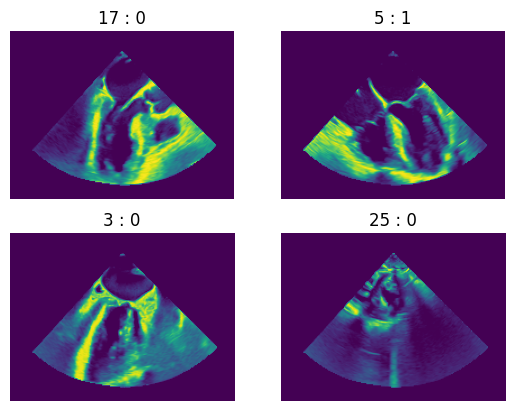

In [17]:
visualize_model(model,dataloaders['test'])

 visualize model predictions on test data

In [12]:
# functions
def plot_auroc (y_actual, y_scores, title):
    fpr, tpr, _thresholds = roc_curve(y_actual, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(2, 2))
    plt.plot(
        fpr,
        tpr,
        linewidth=2
    )
    plt.xlim([0, 1])
    plt.ylim([0, 1])
    plt.title(f'{title} AUROC: {roc_auc:.4f}')
    plt.savefig(f'../data/{title}.png', pad_inches=0, bbox_inches=None, dpi=300)
    plt.show()


def evaluate_multiclass_model(model, dataloader):
    
    was_training = model.training
    model.eval()
    with torch.no_grad():
        for i in range(len(class_names)):
            print(class_names[i])
            test_predictions = []
            test_labels = []
            for j, (inputs, labels) in tqdm(enumerate(dataloader)):
                classes = labels
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                
                # print(outputs[classes])
                                
                if labels==i:
                    label_binary = 1
                else:
                    label_binary = 0

                if labels==torch.argmax(outputs):
                    output_binary = float(torch.max(outputs).cpu())
                    # print(f'right  :{output_binary}')
                else:
                    output_binary = float((torch.sum(outputs).cpu()-torch.max(outputs).cpu()))
                    # print(f'wrong  :{output_binary}')

                test_predictions.append(output_binary)
                test_labels.append(label_binary)
            # print(test_predictions)
            # print(test_labels)
            plot_auroc(test_labels, test_predictions, 'Test data')
            
    
#     test_labels_predicted = np.reshape(np.round(test_predictions), -1).astype(int)
#     cm = confusion_matrix(test_labels, test_labels_predicted)
#     disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['four_chamber', 'other'])
#     disp.plot(values_format='d')
#     plt.title('Confusion matrix')
#     plt.savefig('../data/confusion_matrix.png', pad_inches=0, bbox_inches=None, dpi=200)
#     plt.show()
    
def evaluate_model(model, dataloader):
    was_training = model.training
    model.eval()
    test_predictions = []
    test_labels = []
    with torch.no_grad():
        for i, (inputs, labels) in tqdm(enumerate(dataloader)):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            test_predictions.append(outputs[:,1].cpu().numpy())
            test_labels.append(labels.cpu().numpy())
            
    plot_auroc(test_labels, test_predictions, 'Test data')
    
    test_labels_predicted = np.reshape(np.round(test_predictions), -1).astype(int)
    cm = confusion_matrix(test_labels, test_labels_predicted)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(values_format='d')
    plt.title('Confusion matrix')
    plt.savefig('../data/confusion_matrix.png', pad_inches=0, bbox_inches=None, dpi=200)
    plt.show()
    
    return (test_labels_predicted == 0) & (test_labels == 1)

In [ ]:
import re


def evaluate_model_clipwise(model, test_dataset):
    
    indice_order = index_natsorted(test_dataset.imgs)
    test_dataset_ordered = torch.utils.data.Subset(test_dataset, indices=indice_order)
    # test_dataloader = torch.utils.data.DataLoader(test_dataset_ordered, batch_size=1, shuffle=False, num_workers=1)
    
    regex = r"^[^_]*_[^_]*_"

    was_training = model.training
    model.eval()
    test_predictions = []
    test_labels = []
    

    string = ""
    clip_predictions = []
    clip_labels = []
    
    with torch.no_grad():
        for i, (inputs, labels) in tqdm(enumerate(test_dataset_ordered)):
            new_string = os.path.split(test_dataset_ordered.dataset.imgs[i][0])[1]
            match = re.search(regex, new_string).group(0)
            if string != match:
                string = match
                if i != 0:
                    test_predictions.append(clip_predictions)
                    test_labels.append(clip_labels)
                    clip_predictions = []
                    clip_labels = []
            
            inputs = torch.unsqueeze(inputs, dim=0).to(device)
            labels = torch.tensor(labels).to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            clip_predictions.append(outputs[:,1].cpu().numpy())
            clip_labels.append(labels.cpu().numpy())
            
            # if i == 3000: break
                                    
    test_predictions = [sum(predictions)/len(predictions) for predictions in test_predictions]
    test_labels = [sum(labels)/len(labels) for labels in test_labels]
    
    plot_auroc(test_labels, test_predictions, 'Test data')
    
    test_labels_predicted = np.reshape(np.round(test_predictions), -1).astype(int)
    cm = confusion_matrix(test_labels, test_labels_predicted)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['other',selected_class])
    disp.plot(values_format='d')
    plt.title('Confusion matrix')
    # plt.savefig('../data/confusion_matrix.png', pad_inches=0, bbox_inches=None, dpi=200)
    plt.show()
    
    return test_labels_predicted, np.array(test_labels)

In [ ]:
test_labels_predicted, test_labels = evaluate_model_clipwise(model, test_dataset)

In [ ]:
false_positives = (test_labels_predicted == 0) & (test_labels == 1)
false_negatives = (test_labels_predicted == 1) & (test_labels == 0)

fpos_indices = list(np.where(false_positives)[0])
fneg_indices = list(np.where(false_negatives)[0])

 Examples of false positives

In [ ]:
def indices_by_clip(clip_index_list, test_dataset):
    indice_order = index_natsorted(test_dataset.imgs)
    test_dataset_ordered = torch.utils.data.Subset(test_dataset, indices=indice_order)

    string = ''
    indices = []
    frames_list = []
    
    regex = r"^[^_]*_[^_]*_"

    count = -1
    for i in tqdm(range(len(test_dataset_ordered))):
        path = test_dataset_ordered.dataset.imgs[i][0]
        new_string = os.path.split(path)[1]
        match = re.search(regex, new_string).group(0)
        if string != match: # if at new video clip, increment count
            string = match
            if count in clip_index_list:
                indices.append(frames_list.copy()) # if switching to a new clip and count is in fpositives, append the current frames list and reset
                frames_list = []
            count += 1
        if count in clip_index_list: # if clip in list of false positives, append frame index to frames_list
            frames_list.append(i)
    
    return indices
    
def display_image_subset(clip_index_list, test_dataset, title = None):
    
    indices = indices_by_clip(clip_index_list, test_dataset)
    
    indice_order = index_natsorted(test_dataset.imgs)
    test_dataset_ordered = torch.utils.data.Subset(test_dataset, indices=indice_order)

    rng = np.random.default_rng()
    numrows = max(len(clip_index_list),2)
    fig, ax = plt.subplots(numrows, 4, tight_layout=True, figsize=(10, 6))
    if title: plt.suptitle(title)

    for i in range(len(indices)):
        disp_indices = rng.choice(indices[i], 4, replace=False)
        ax[i][0].imshow(test_dataset_ordered[disp_indices[0]][0][0,:,:], cmap = 'gray')
        ax[i][1].imshow(test_dataset_ordered[disp_indices[1]][0][0,:,:], cmap = 'gray')
        ax[i][2].imshow(test_dataset_ordered[disp_indices[2]][0][0,:,:], cmap = 'gray')
        ax[i][3].imshow(test_dataset_ordered[disp_indices[3]][0][0,:,:], cmap = 'gray')
    plt.show()


In [ ]:
display_image_subset(fneg_indices, test_dataset, title = 'me bicaval, false negatives')

In [ ]:
display_image_subset(fpos_indices, test_dataset, title = 'me bicaval, false positives')

In [ ]:
def display_image_subset(clip_index_list, test_dataset):
    
    indices = indices_by_clip(clip_index_list, test_dataset)
    
    indice_order = index_natsorted(test_dataset.imgs)
    test_dataset_ordered = torch.utils.data.Subset(test_dataset, indices=indice_order)

    rng = np.random.default_rng()
    numrows = len(
    fig, ax = plt.subplots(2, 4, tight_layout=True, figsize=(10, 4))

    for i in range(len(indices)):
        disp_indices = rng.choice(indices[i], 4, replace=False)
        ax[i][0].imshow(test_dataset_ordered[disp_indices[0]][0][0,:,:])
        ax[i][1].imshow(test_dataset_ordered[disp_indices[1]][0][0,:,:])
        ax[i][2].imshow(test_dataset_ordered[disp_indices[2]][0][0,:,:])
        ax[i][3].imshow(test_dataset_ordered[disp_indices[3]][0][0,:,:])
    plt.show()

In [ ]:
disp_indices

In [ ]:
plt.imshow(test_dataset_ordered[i][0][0,:,:])

 Examples of false negatives

In [ ]:
false_negatives_ind = (test_labels_predicted == 1) & (test_labels == 0)
false_negatives = np.random.choice(np.where(false_negatives_ind)[0], 16)

plt.figure(figsize=(10, 10))
i = 0
for index in false_negatives:
  ax = plt.subplot(4, 4, i + 1)
  ax.set_aspect('equal')
  plt.imshow(test_data[index][0].astype('uint8'))
  plt.axis('off')
  i += 1
plt.savefig('../data/test_false_negatives.png', pad_inches=0, bbox_inches=None, dpi=300)
plt.show()




In [ ]:
print(model.summary())

In [ ]:
plot_model(model, to_file='../data/model.png', show_shapes=True, show_layer_names=True)